<a href="https://colab.research.google.com/github/dennicenteno18/IA_con_estilo/blob/main/Tareas/Clasificaci%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

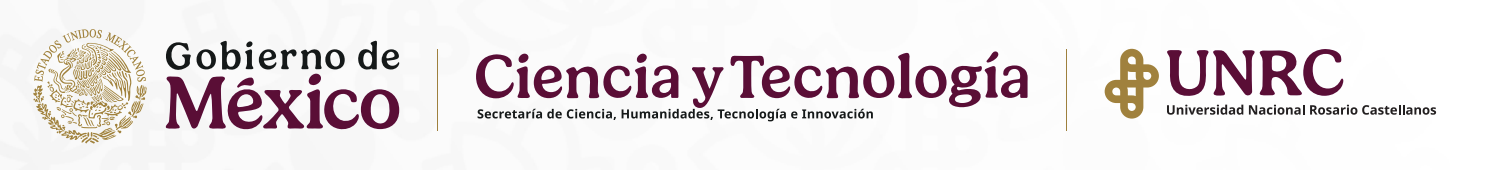

**Octubre 2026**.   

Mariana Dennis Garcia Centeno

# ***Introducción***

* Retoma el ejemplo de clasificación del género musical de una canción de Spotify realizado en clase.
* Mejora la exactitud () de la red neuronal en al menos un 5 % con respecto al 64 % obtenido en clase. Por lo tanto, deberás alcanzar un de .
* Describe con tus propias palabras los cambios que realizaste en el modelo para mejorar su desempeño.
* Indica cuántos intentos o experimentos necesitaste para alcanzar el resultado obtenido.
* No existe una única solución: puedes probar diferentes configuraciones y estrategias para mejorar el desempeño de la red neuronal.
* Sigue las indicaciones del repositorio de GitHub de referencia para organizar y documentar tu práctica: https://github.com/mevangelista-alvarado/template_para_redes_neuronales_curso
* Entrega el enlace a tu repositorio de GitHub.
* Utiliza Google Colab para realizar tus experimentos y guarda el Notebook en tu repositorio de GitHub.
* Prueba diferentes configuraciones, como el número de capas y neuronas, las funciones de activación, el número de épocas o los parámetros de entrenamiento.
* Registra los resultados de tus experimentos para comparar el desempeño de cada configuración.
* Mantén una separación adecuada entre los datos de entrenamiento y prueba para evaluar el modelo correctamente.
* Explica cada cambio realizado y justifica por qué consideras que contribuyó a mejorar el .

#**Desarrollo**

In [34]:
import pandas as pd

url = "https://raw.githubusercontent.com/mevangelista-alvarado/datasets/refs/heads/main/spotify_songs.csv"
df = pd.read_csv(url)

* Importamos pandas y cargamos el dataset que vendría siendo nuestro link de Spotify.

In [35]:
df

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,...,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,...,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,...,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,...,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


In [36]:
df.shape

(114000, 21)

* Con esas dos celdas de código podemos observar el contenido de nuestro dataset el segundo nos muestra la cantidad de contenido que tiene guardado específicamente filas y columnas.

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

* Como su nombre lo indica, podemos observar toda la información que puede tener las canciones como tempo, el nombre del artista, el album al que pertenece, entre otros.

In [38]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


* Nos muestra el resumen del primer cuadro que se encuentra ubicado en la primera fila y las columnas númericas que es la primera columna.

In [39]:
df.describe(include="object")

,track_id,artists,album_name,track_name,track_genre
count,114000,113999,113999,113999,114000
unique,89741,31437,46589,73608,114
top,6S3JlDAGk3uu3NtZbPnuhS,The Beatles,Alternative Christmas 2022,Run Rudolph Run,acoustic
freq,9,279,195,151,1000


* Ahora que pusimos el "objec" esto quiere indicar que el resumen estadístico será de datos tipo texto.

In [40]:
df['track_genre'].unique()

array(['acoustic', 'afrobeat', 'alt-rock', 'alternative', 'ambient',
       'anime', 'black-metal', 'bluegrass', 'blues', 'brazil',
       'breakbeat', 'british', 'cantopop', 'chicago-house', 'children',
       'chill', 'classical', 'club', 'comedy', 'country', 'dance',
       'dancehall', 'death-metal', 'deep-house', 'detroit-techno',
       'disco', 'disney', 'drum-and-bass', 'dub', 'dubstep', 'edm',
       'electro', 'electronic', 'emo', 'folk', 'forro', 'french', 'funk',
       'garage', 'german', 'gospel', 'goth', 'grindcore', 'groove',
       'grunge', 'guitar', 'happy', 'hard-rock', 'hardcore', 'hardstyle',
       'heavy-metal', 'hip-hop', 'honky-tonk', 'house', 'idm', 'indian',
       'indie-pop', 'indie', 'industrial', 'iranian', 'j-dance', 'j-idol',
       'j-pop', 'j-rock', 'jazz', 'k-pop', 'kids', 'latin', 'latino',
       'malay', 'mandopop', 'metal', 'metalcore', 'minimal-techno', 'mpb',
       'new-age', 'opera', 'pagode', 'party', 'piano', 'pop-film', 'pop',
       'pow

* Podemos observar todos los generos músicales.

In [41]:
df['track_genre'].value_counts()

,count
track_genre,
acoustic,1000
afrobeat,1000
alt-rock,1000
alternative,1000
ambient,1000
...,...
techno,1000
trance,1000
trip-hop,1000


* Ahora que tenemos el "value_count" podemos saber cuantas canciones existen de cada género.

In [42]:
generos = [
    'pop',
    'rock',
    'jazz',
    'classical',
    'hip-hop'
]

* Para este ejercicio utilizaremos solo estos 5 géneros.

In [43]:
df = df[df['track_genre'].isin(generos)].copy()

In [44]:
df.shape

(5000, 21)

* Filtramos los datos del dataFrame que es referente a las canciones con los géneros que seleccionamos.

In [45]:
df['track_genre'].value_counts()

,count
track_genre,
classical,1000
hip-hop,1000
jazz,1000
pop,1000
rock,1000


In [46]:
df.shape

(5000, 21)

* Podemos comprobar el resultado si coincide.

In [47]:
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

* En esta celda estan las variables que representan las características de la canción.

In [48]:
df[features].head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
16000,0.643,0.268,-15.073,0.0900,0.593,0.000002,0.316,0.620,143.813
16001,0.484,0.898,-4.132,0.1640,0.365,0.000000,0.091,0.680,91.975
16002,0.608,0.638,-6.008,0.0292,0.581,0.017200,0.448,0.439,140.109
16003,0.695,0.293,-16.278,0.0431,0.596,0.015800,0.132,0.637,143.804
16004,0.583,0.308,-18.303,0.0465,0.581,0.010600,0.257,0.241,118.226


* En la tabla podemos observar las variables que puede tener una canción. En la primera columna es el número de los géneros que escogimos.

In [49]:
X = df[features]

In [50]:
X.shape

(5000, 9)

* Construimos *"X"* utilizando las características musicales.

In [51]:
import pandas as pd

y = df['track_genre']
Y = pd.get_dummies(y).values

In [52]:
y

,track_genre
16000,classical
16001,classical
16002,classical
16003,classical
16004,classical
...,...
91995,rock
91996,rock
91997,rock
91998,rock


In [53]:
Y

array([[ True, False, False, False, False],
       [ True, False, False, False, False],
       [ True, False, False, False, False],
       ...,
       [False, False, False, False,  True],
       [False, False, False, False,  True],
       [False, False, False, False,  True]], shape=(5000, 5))

In [54]:
pd.get_dummies(y).columns

Index(['classical', 'hip-hop', 'jazz', 'pop', 'rock'], dtype='object')

* Nos dan las variables en tipo objeto y nos dan tanto las canciones con su respectivo género y también podemos observa la matriz como tipo booleanos.

In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

* Usamos el 80% para entrenar y el 20% para evaluar.

Además usamos "stratify=Y" para intentar conservar la cantidad de cada género tanto para el entrenamiento como la prueba.

In [56]:
print (X_train.shape)
print (X_test.shape)

(4000, 9)
(1000, 9)


In [57]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

* Normalizamos las características. Además de transformar las variables para que tengamos una desviación estándar = 1 y la media = 0

# ***Modelo (Red Neuronal)***

In [58]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

modelo_nuevo = Sequential([
    Dense(64, input_shape=(X_train.shape[1],), activation='relu'),
    Dense(32, activation='relu'),
    Dense(5, activation='softmax'), #5 géneros y 5 neuronas
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [63]:
from tensorflow.keras.optimizers import Adam

modelo_nuevo.compile(
    optimizer=Adam(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [70]:
history_base = modelo_nuevo.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=2,
    validation_data=(X_test, y_test),
    verbose=0,
)

In [71]:
loss_base, acc_base = modelo_nuevo.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Experimento 1 (Base) Accuracy: {acc_base:.4f} ({acc_base*100:.2f}%)")

Experimento 1 (Base) Accuracy: 0.6580 (65.80%)


In [74]:
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

modelo_nuevo = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(5, activation='softmax')
])

In [75]:
from tensorflow.keras.optimizers import Adam

modelo_nuevo.compile(
    optimizer=Adam(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_dropout = modelo_nuevo.fit(
    X_train_scaled,
    y_train,
    epochs=10,
    batch_size=2,
    validation_data=(X_test_scaled, y_test),
    verbose=0
)

loss_drop, acc_drop = modelo_nuevo.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Experimento 2 (Dropout) Accuracy: {acc_drop:.4f} ({acc_drop*100:.2f}%)")

Experimento 2 (Dropout) Accuracy: 0.6220 (62.20%)


In [76]:
modelo_nuevo.compile(optimizer=Adam(learning_rate=0.001),
                        loss='categorical_crossentropy',
                        metrics=['accuracy'])

In [77]:
history_nuevo = modelo_nuevo.fit(X_train_scaled, y_train, epochs=25, batch_size=64,
                                       validation_data=(X_test_scaled, y_test), verbose=1)

Epoch 1/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.6237 - loss: 0.9595 - val_accuracy: 0.6280 - val_loss: 0.8844
Epoch 2/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6295 - loss: 0.9458 - val_accuracy: 0.6390 - val_loss: 0.8783
Epoch 3/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6288 - loss: 0.9513 - val_accuracy: 0.6390 - val_loss: 0.8719
Epoch 4/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6355 - loss: 0.9207 - val_accuracy: 0.6420 - val_loss: 0.8687
Epoch 5/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6335 - loss: 0.9051 - val_accuracy: 0.6430 - val_loss: 0.8649
Epoch 6/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6380 - loss: 0.9158 - val_accuracy: 0.6420 - val_loss: 0.8636
Epoch 7/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6298 - loss: 0.9094 - val_accuracy: 0.6440 - val_loss: 0.8623
Epoch 8/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6395 - loss: 0.8926 - val_accuracy: 0.6430 - val_los

* El "batch_size" lo aumente a 64 ya que el valor 2 no era muy funcional. En las épocas se le aumentaron 25 para una respuesta completa. El "learning_rate" esta en un 0.001 para lacaída mas agradable.

In [79]:
loss_nuevo, acc_nuevo = modelo_nuevo.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Experimento 2 (Mejorado) Accuracy: {acc_nuevo:.4f} ({acc_nuevo*100:.2f}%)")
print(f"Mejora absoluta respecto a la línea base: {(acc_nuevo - acc_base)*100:.2f}%")

Experimento 2 (Mejorado) Accuracy: 0.6490 (64.90%)
Mejora absoluta respecto a la línea base: -0.90%


In [80]:
print(f"Experimento 2 (Mejorado) Accuracy: {acc_nuevo:.4f} ({acc_nuevo*100:.2f}%)")

Experimento 2 (Mejorado) Accuracy: 0.6490 (64.90%)


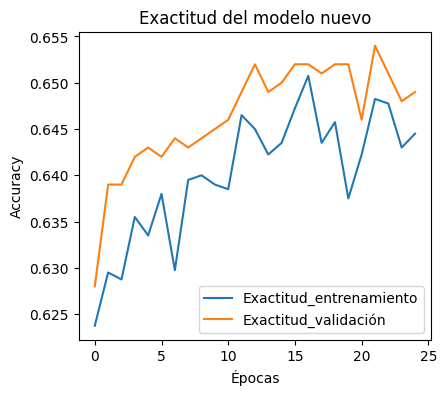

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history_nuevo.history['accuracy'], label='Exactitud_entrenamiento')
plt.plot(history_nuevo.history['val_accuracy'], label='Exactitud_validación')
plt.title('Exactitud del modelo nuevo')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()


* En esta gráfica podemos observar que las dos lineas van juntas y están aprendiendo muy bien.

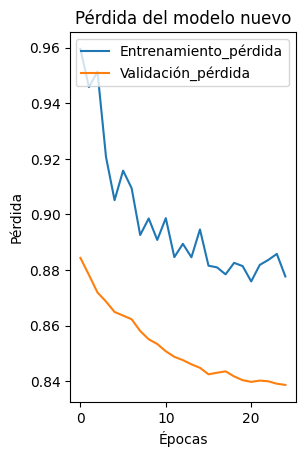

In [82]:
plt.subplot(1, 2, 2)
plt.plot(history_nuevo.history['loss'], label='Entrenamiento_pérdida')
plt.plot(history_nuevo.history['val_loss'], label='Validación_pérdida')
plt.title('Pérdida del modelo nuevo')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.show()

* En esta segunda gráfica nos indica como se puede equivocar el modelo, pero lo importante es que van hacia abajo las dos lineas juntas, diciendo que esta bajando el márgen de error.

In [84]:
import numpy as np

In [85]:
nueva_cancion_scaled = scaler.transform(nueva_cancion.to_numpy())

In [86]:
# Predicción manual con valores realistas
nueva_cancion = pd.DataFrame([{
    'danceability': 0.70, 'energy': 0.65, 'loudness': -5.5, # Loudness corregido a negativo
    'speechiness': 0.05, 'acousticness': 0.20, 'instrumentalness': 0.00,
    'liveness': 0.15, 'valence': 0.75, 'tempo': 120.0
}])
nueva_cancion = nueva_cancion[features] # Asegurar orden de columnas
nueva_cancion_scaled = scaler.transform(nueva_cancion)

probabilidades = modelo_nuevo.predict(nueva_cancion_scaled, verbose=0)[0]
clase_predicha = np.argmax(probabilidades)
generos_lista = pd.get_dummies(y).columns.tolist()
print(f"Género predicho: {generos_lista[clase_predicha].upper()}\n")
print("Probabilidades:")
for genero, prob in zip(generos_lista, probabilidades):
    print(f"  {genero.capitalize():12s}: {prob:.2%}")

Género predicho: CLASSICAL

Probabilidades:
  Classical   : 94.50%
  Hip-hop     : 0.00%
  Jazz        : 0.00%
  Pop         : 5.33%
  Rock        : 0.16%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


# **Conclusión**

* Se realizo dos intentos para el resultado final. Definimos las características de las canciones y también usamos los 5 géneros que escogimos que representa un 100%.

#Referencias

* Equipo de desarrollo de Pandas. (s.f.)*. pandas.DataFrame.isin.* Documentación de Pandas. Recuperado el 27 de octubre de 2026, de https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isin.html
* Equipo de desarrollo de Pandas. (s.f.)*. pandas.DataFrame.describe.* Documentación de Pandas. Recuperado el 27 de octubre de 2026, de https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html